# 02 — What peeking does to false positives (A/A simulation)

**The interview question this answers:** *"The PM checked the dashboard every day and stopped the
test the moment it hit p < 0.05. What's wrong with that?"*

**The idea:** take only the **No E-Mail** customers and split them at random into two fake arms.
Nobody got anything different, so **there is no real effect** — every "winner" is a false positive.
Then count how often you'd declare one:
1. with **one look** at the end (should be about 5%),
2. with **20 looks**, stopping at the first p < 0.05 (will be much higher),
3. with a **stricter early threshold** that you tune until it is back at 5%.

**Honesty note for the write-up:** the data has no arrival timestamps, so the order customers
"arrive" in is a random shuffle. Say so.

Fill in every `___`. Hints are in the comments. A cell with a `___` left in it will error — that is expected until you fill it.

In [1]:
import pandas as pd
import numpy as np
import scipy.stats
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/hillstrom.csv")
rng = np.random.default_rng(2026)   # fixed seed: anyone who reruns this gets the same numbers

In [2]:
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


## Step 1 — Keep only the control arm

Why only No E-Mail? Because nobody in it got an email, so any difference between two random halves
of it is **pure chance**. That's what makes every "significant" result a false positive.

In [4]:
control = df[df['segment'] == 'No E-Mail']['spend'].to_numpy()  # a numpy array of `spend` for customers whose segment is "No E-Mail". Hint: .to_numpy()
print(len(control), control.mean())

21306 0.6527893551112361


## Step 2 — One fake experiment, by hand

Shuffle the control customers, cut the shuffled list in half, call the halves A and B, and run
Welch's t-test (the test from your pre-registration) on the full halves.

Run the cell a few times. The p-value jumps around — that's what "no real effect" looks like.

In [8]:
shuffled = rng.permutation(control)                       # Hint: rng.permutation(control)
half = len(shuffled) // 2
a, b = shuffled[:half], shuffled[half:]
result = scipy.stats.ttest_ind(a, b, equal_var=False)   # Welch = do NOT assume equal variances
print(result.statistic, result.pvalue)

-0.7965203499385252 0.42573881210478576


## Step 3 — Peeking: test 20 times as the data "arrives"

Imagine the customers arrive in the shuffled order. At **look k** (k = 1 … 20) you've seen the first
k/20 of each arm, and you run the test on everything seen **so far** (cumulative, not just the new batch).

We'll keep the **t-statistic** at each look instead of the p-value. Reason: the stricter boundary
in Step 5 is written as a cutoff on |t|, and with thousands of customers per arm the t-statistic
behaves like a z-score, so "p < 0.05, two-sided" is the same as **|t| > 1.96**.

In [9]:
K = 20

def peek_tstats(a, b, K=20):
    """Return an array of K t-statistics, one per look, each on the data seen so far."""
    tstats = []
    for k in range(1, K + 1):
        m = int(len(a) * k / K)              # how many customers per arm have arrived by look k
        t = scipy.stats.ttest_ind(a[:m], b[:m], equal_var=False).statistic                              # Welch t-statistic on a[:m] vs b[:m]. Hint: .statistic
        tstats.append(t)
    return np.array(tstats)

peek_tstats(a, b)    # 20 numbers; look at how they wander

array([-1.33558094, -1.1625258 , -1.33680743, -1.79312365, -1.45828774,
       -0.6958556 , -0.98385782, -1.08088642, -0.79878336, -0.55933899,
       -0.41534342, -0.80158708, -0.71427008, -0.82021361, -0.93183489,
       -0.79085097, -0.69099485, -0.39342024, -0.62405699, -0.79652035])

## Step 4 — Repeat it 2,000 times

Each simulation: shuffle, split, get the 20 t-statistics. Store them all in one table `T`
(2,000 rows × 20 looks) — Step 5 reuses it, so you only simulate once.

This runs 40,000 t-tests; expect it to take a little while (well under a minute).

**You may see a `RuntimeWarning`.** At look 1 there are only ~530 customers per arm, and once in a while neither half has a single buyer — every value is $0, so the t-statistic is undefined (`nan`). A `nan` never counts as crossing the cutoff, which is the right outcome: no data, no winner. It's another sign of the heavy tail, worth a line in your limits.

In [10]:
N_SIMS = 2000
T = np.zeros((N_SIMS, K))

for i in range(N_SIMS):
    shuffled = rng.permutation(control)
    a, b = shuffled[:half], shuffled[half:]
    T[i] = peek_tstats(a,b)                       # the 20 t-statistics for this simulation

T = np.abs(T)                        # two-sided: only the size matters, not the sign

In [26]:
print(T[:5, 9:11])
print(np.corrcoef(T[:, 9], T[:, 10])[0, 1])
print(pd.Series(T[:, 0]).corr(pd.Series(T[:, 19])))

[[0.19708969 0.15921595]
 [1.98792818 1.23433613]
 [2.14823926 2.10976815]
 [0.37097525 0.0306876 ]
 [0.90372866 1.06808354]]
0.8871003655868952
0.10095899857506324


In [11]:
# One look: only the LAST column counts.
fp_one_look = (T[:,-1] > 1.96).mean()                    # share of simulations where the final |t| > 1.96. Hint: (T[:, -1] > 1.96).mean()

# Peeking: you stop at the FIRST look that crosses, so a simulation counts if ANY look crosses.
fp_peeking = (T > 1.96).any(axis=1).mean()                     # Hint: (T > 1.96).any(axis=1).mean()

print(f"false positive rate, one look:  {fp_one_look:.1%}")
print(f"false positive rate, 20 looks:  {fp_peeking:.1%}")

false positive rate, one look:  4.0%
false positive rate, 20 looks:  22.6%


**Questions — answer in your own words:**
1. Why does peeking raise the false positive rate, when each single look is still a 5% test?
2. Why are the t-statistics at neighbouring looks similar to each other? (Hint: how much of the data do look 10 and look 11 share?) Does that make the peeking rate higher or lower than if the 20 tests were independent?

*Your answers:* 
1. Each look is 5% on its own, but stopping at the first crossing means you win if any of the 20 crosses, so the chances add up. 22.6% with peeking vs 4.0% with one look
2. Neighbouring looks share most of their data (91%), so their t-statistics move together, and that makes the peeking rate lower than 64%. It's still far above 5%.

## Step 5 — Fix it with a stricter early boundary

Peeking is only a problem because early looks use the same 1.96 cutoff as the final one. An
**O'Brien-Fleming-shaped** boundary makes early looks demand much stronger evidence:

$$\text{cutoff at look } k = c \cdot \sqrt{K / k}$$

- At look 1 the cutoff is $c\sqrt{20} \approx 4.5c$ — very hard to cross on a fluke.
- At the last look (k = K) the cutoff is just $c$.

You choose **c** by simulation: try a range of values and pick the **smallest c** that brings the
false positive rate back to 5% or below. Smallest, because a bigger c costs you power.

In [17]:
k = np.arange(1, K + 1)

def boundary_rate(c):
    cutoffs = c * np.sqrt(K/k)                    # the 20 cutoffs for this c. Hint: c * np.sqrt(K / k)
    return (T > cutoffs).any(axis=1).mean()                       # share of simulations where ANY look crosses its own cutoff. Hint: compare T to cutoffs

for c in [1.96, 2.0, 2.05, 2.1, 2.15, 2.2]:
    print(c, f"{boundary_rate(c):.1%}")

1.96 6.7%
2.0 5.9%
2.05 5.5%
2.1 4.6%
2.15 4.0%
2.2 3.5%


In [18]:
c_grid = np.arange(1.90, 2.40, 0.005)
rates = np.array([boundary_rate(c) for c in c_grid])
c_star = c_grid[rates <= 0.05].min()                         # the smallest c in c_grid whose rate is <= 0.05. Hint: c_grid[rates <= 0.05].min()
print(f"calibrated c = {c_star:.3f}, false positive rate = {boundary_rate(c_star):.1%}")

calibrated c = 2.070, false positive rate = 5.0%


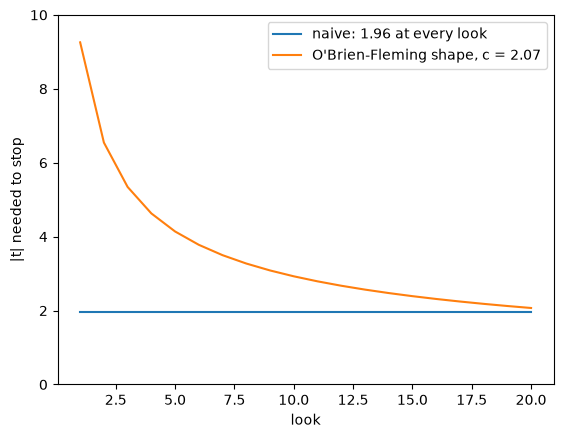

In [19]:
# Picture: the flat 1.96 line vs your boundary.
plt.plot(k, np.full(K, 1.96), label="naive: 1.96 at every look")
plt.plot(k, c_star * np.sqrt(K / k), label=f"O'Brien-Fleming shape, c = {c_star:.2f}")
plt.xlabel("look"); plt.ylabel("|t| needed to stop"); plt.ylim(0, 10); plt.legend()
plt.show()

## Step 6 — Check c on fresh simulations

You tuned c on the same 2,000 simulations you're now scoring it on, which flatters it slightly
(the same reason you test a model on held-out data). Run 2,000 **new** simulations and check the
rate with `c_star` held fixed.

In [25]:
T_new = np.zeros((N_SIMS, K))
for i in range(N_SIMS):
    shuffled = rng.permutation(control)
    a, b = shuffled[:half], shuffled[half:]
    T_new[i] = peek_tstats(a,b)                              # same as Step 4: shuffle, split, fill row i of T_new
T_new = np.abs(T_new)

fp_fresh = (T_new > (c_star * np.sqrt(K / k))).any(axis=1).mean()                       # rate on T_new using c_star's cutoffs
print(f"fresh-simulation false positive rate with c = {c_star:.3f}: {fp_fresh:.1%}")

fresh-simulation false positive rate with c = 2.070: 5.7%


## Step 7 — How precise are these rates?

A simulated rate is itself an estimate. Its standard error is $\sqrt{p(1-p)/N}$, with N the number of simulations.

In [24]:
se = np.sqrt((0.05 * (1 - 0.05)) / N_SIMS)                             # standard error of a 5% rate estimated from N_SIMS simulations
print(f"a 5% rate from {N_SIMS} simulations is accurate to about ±{1.96 * se:.1%}")

a 5% rate from 2000 simulations is accurate to about ±1.0%


## Interpretation

Write 4–6 sentences. Prompts:
- One look vs 20 looks: the two false positive rates, in plain words.
- Your calibrated c, the cutoff it needs at look 1 and at look 20, and the fresh-simulation rate.
- The price: c is above 1.96, so at the final look you need *more* evidence than a single-look test. What does that cost you?
- Limits: arrival order is simulated (no timestamps); spend is ~99% zeros, so at early looks
  (about 530 customers per arm, only a handful of buyers) the t-test's normal approximation is rough.
- Note that this check uses only the control arm, so it reveals nothing about the email effects.

*Your interpretation:*
With a single look at the end, the A/A test declared a false winner in 4.0% of 2,000 simulations, within simulation noise (about ±1 percentage point) of the promised 5%. Checking 20 times and stopping at the first p < 0.05 raised that to 22.6%, more than four times as many false winners, even though no real effect existed. An O'Brien-Fleming-shaped boundary with c calibrated to 2.07 brought the rate back to 5.0%. It demands |t| > 9.3 at the first look and |t| > 2.07 at the last, and on 2,000 fresh simulations it held at 5.7% within the ±1 percentage point simulation noise. The price is power: at the final look the test needs |t| > 2.07 instead of 1.96, so a real effect that would only just pass a single-look test can be missed. In exchange, the test can stop early when the evidence is overwhelming. Limits: there are no arrival timestamps, so the order customers arrive in is a random shuffle. Spend is about 99% zeros, so early looks of about 530 customers per arm contain only a handful of buyers, and the t-test's normal approximation is rough there. This check uses only the No E-Mail arm, so it says nothing about whether either email worked.
